In [ ]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
import h5py

In [33]:
results_dir = Path("num_results_loc/computed_manifolds")
poincare_dir = Path("num_results_loc/poincare_plots")

configs = list(range(11, 20)) + list(range(110, 124)) + [21, 22, 23]

manifolds = {}
parameters = {}
poincare_plots = {}

for config_id in configs:
    # Load manifolds
    path = results_dir / f"manifolds_{config_id}.npz"
    with np.load(path) as data:
        manifolds[config_id] = {
            key: data[key].copy()
            for key in data.files
        }

    # Load parameters
    path_json = results_dir / f"parameters_{config_id}.json"
    with open(path_json, "r", encoding="utf-8") as f:
        parameters[config_id] = json.load(f)

    # Load Poincare trajectories
    path_poincare = poincare_dir / f"pplot_{config_id}.npz"
    with np.load(path_poincare) as data:
        poincare_plots[config_id] = data["hits"].copy()

In [8]:
temperature_dir = Path("num_results_loc/FaADE")

def plot_temperature(
    ax,
    params,
    t_f=0.01,
    k_values=(4.0, 6.0, 8.0, 10.0, 12.0),
    nx=201,
    colors=("red", "orange", "green", "purple", "blue")
):
    """
    Plot temperature profiles on a secondary y-axis.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Main axis containing Poincare plot and manifolds.
    params : dict
        Configuration parameters.
    t_f : float
        Final simulation time.
    k_values : iterable
        Exponents defining kappa_perp/kappa_parallel = 10^(-k).
    nx : int
        Spatial resolution.
    """

    ax_T = ax.twinx()

    delta1 = params["delta1"]
    delta2 = params["delta2"]
    iota = params["iota_prime"]

    for exp_k, color in zip(k_values, colors):

        filename = (
            f"2I_k{float(exp_k)}_tf{t_f}_"
            f"d{delta1}_{delta2}_res{nx}_"
            f"m1_dT_iota{float(iota)}_Neumann.jld2"
        )

        path = temperature_dir / filename

        if not path.exists():
            print(f"Temperature file not found: {filename}")
            continue

        with h5py.File(path, "r") as f:
            x_mid = np.asarray(f["x_mid"]).squeeze()
            u_mid = np.asarray(f["u_mid"]).squeeze()

        ax_T.plot(
            x_mid,
            u_mid,
            color=color,
            linewidth=2,
            label=rf"$\kappa_\perp/\kappa_\parallel = 10^{{-{int(exp_k)}}}$",
            zorder=4
        )

    ax_T.set_ylabel(r"$T(x)$")
    ax_T.set_xlim(0, 2)

    return ax_T

In [40]:
def plot_configuration(
    config_id,
    markersize=3,
    poincare=True,
    unwrapped=False,
    maxs=None,
    maxu=None,
    temperature=False,
    t_f=0.01,
    k_values=(4.0, 6.0, 8.0, 10.0, 12.0),
    ax=None
):

    params = parameters[config_id]
    data = manifolds[config_id]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    else:
        fig = ax.figure

    # --------------------------------------------------
    # 1. Poincare plot
    # --------------------------------------------------

    if poincare:
        if config_id not in poincare_plots:
            raise ValueError(
                f"Poincare plot for configuration {config_id} "
                "has not been loaded."
            )

        hits = poincare_plots[config_id]

        for traj in hits:
            ax.scatter(
                traj[:, 0],
                traj[:, 1],
                color="black",
                marker=".",
                s=1.5,
                lw=0,
                alpha=0.35,
                zorder=1
            )

        ax.set_xlim(0, 2)

    # --------------------------------------------------
    # 2. Stable and unstable manifolds
    # --------------------------------------------------

    indices = sorted(
        int(key[len("stable"):])
        for key in data
        if key.startswith("stable")
        and key[len("stable"):].isdigit()
    )

    if maxs is None:
        maxs = [None] * len(indices)

    if maxu is None:
        maxu = [None] * len(indices)

    if len(maxs) != len(indices) or len(maxu) != len(indices):
        raise ValueError(
            f"Configuration {config_id} has {len(indices)} manifolds. "
            "maxs and maxu must have one entry per manifold."
        )

    first_plotted = True

    for j, i in enumerate(indices):

        stable_key = f"stable{i}"
        unstable_key = f"unstable{i}"

        if unwrapped:
            if f"stable_unwrapped{i}" in data:
                stable_key = f"stable_unwrapped{i}"

            if f"unstable_unwrapped{i}" in data:
                unstable_key = f"unstable_unwrapped{i}"

        if stable_key not in data or unstable_key not in data:
            continue

        stable = data[stable_key]
        unstable = data[unstable_key]

        ax.plot(
            stable[:maxs[j], 0],
            stable[:maxs[j], 1],
            color="cyan",
            marker=".",
            markersize=markersize,
            linestyle="",
            label="Stable" if first_plotted else None,
            zorder=2
        )

        ax.plot(
            unstable[:maxu[j], 0],
            unstable[:maxu[j], 1],
            color="magenta",
            marker=".",
            markersize=markersize,
            linestyle="",
            label="Unstable" if first_plotted else None,
            zorder=2
        )

        first_plotted = False

    # --------------------------------------------------
    # 3. Temperature profiles
    # --------------------------------------------------

    if temperature:
        ax_T = plot_temperature(
            ax,
            params,
            t_f=t_f,
            k_values=k_values
        )

    # --------------------------------------------------
    # 4. Figure formatting
    # --------------------------------------------------

    ax.set_title(
        rf"$\delta_1={params['delta1']},\ "
        rf"\delta_2={params['delta2']},\ "
        rf"\iota'={params['iota_prime']}$"
    )

    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2*np.pi)

    ax.set_xlabel("x")
    ax.set_ylabel(r"$\theta$")

    return fig, ax

In [49]:
def plot_configurations(config_ids, ncols=3, figsize_per_subplot=(5, 4), markersize=1,
                        poincare=True, unwrapped=True, temperature=True, t_f=0.01,
                        k_values=(4.0, 6.0, 8.0, 10.0, 12.0), save_name=None):

    n = len(config_ids)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per_subplot[0] * ncols, figsize_per_subplot[1] * nrows),
                             squeeze=False, sharex=True, sharey=True)

    for j, (ax, config_id) in enumerate(zip(axes.flat, config_ids)):

        # Load maxs and maxu for this configuration
        maxpoints_path = results_dir / f"maxpoints_{config_id}.json"
        with open(maxpoints_path, "r", encoding="utf-8") as f:
            maxpoints = json.load(f)

        # Plot configuration
        plot_configuration(config_id, markersize=markersize, poincare=poincare,
                           unwrapped=unwrapped, maxs=maxpoints["maxs"], maxu=maxpoints["maxu"],
                           temperature=temperature, t_f=t_f, k_values=k_values, ax=ax)

        # ax.set_title(f"Configuration {config_id}", fontsize=12)

        # Only display temperature y-axis labels on the rightmost occupied subplot of each row
        if temperature:
            ax_T = fig.axes[-1]

            is_last_in_row = (j % ncols == ncols - 1)
            is_last_subplot = (j == n - 1)

            if not (is_last_in_row or is_last_subplot):
                ax_T.tick_params(axis="y", right=True, labelright=False)
                ax_T.set_ylabel("T(x)")

    # Hide unused subplots
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)

    # Shared temperature legend
    if temperature:
        temperature_axes = [a for a in fig.axes if a not in axes.flat]

        if temperature_axes:
            handles, labels = temperature_axes[0].get_legend_handles_labels()

            if handles:
                fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.01),
                           ncol=len(handles), title="Parallel transport",
                           fontsize=10, title_fontsize=11, frameon=True)

    # Reserve space for shared legend
    if temperature:
        fig.tight_layout(rect=[0, 0.09, 1, 1])
    else:
        fig.tight_layout()

    # Save figure
    if save_name is not None:
        save_dir = Path("Figures/comparisons")
        save_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_dir / f"{save_name}.png", dpi=300, bbox_inches="tight")

    return fig, axes

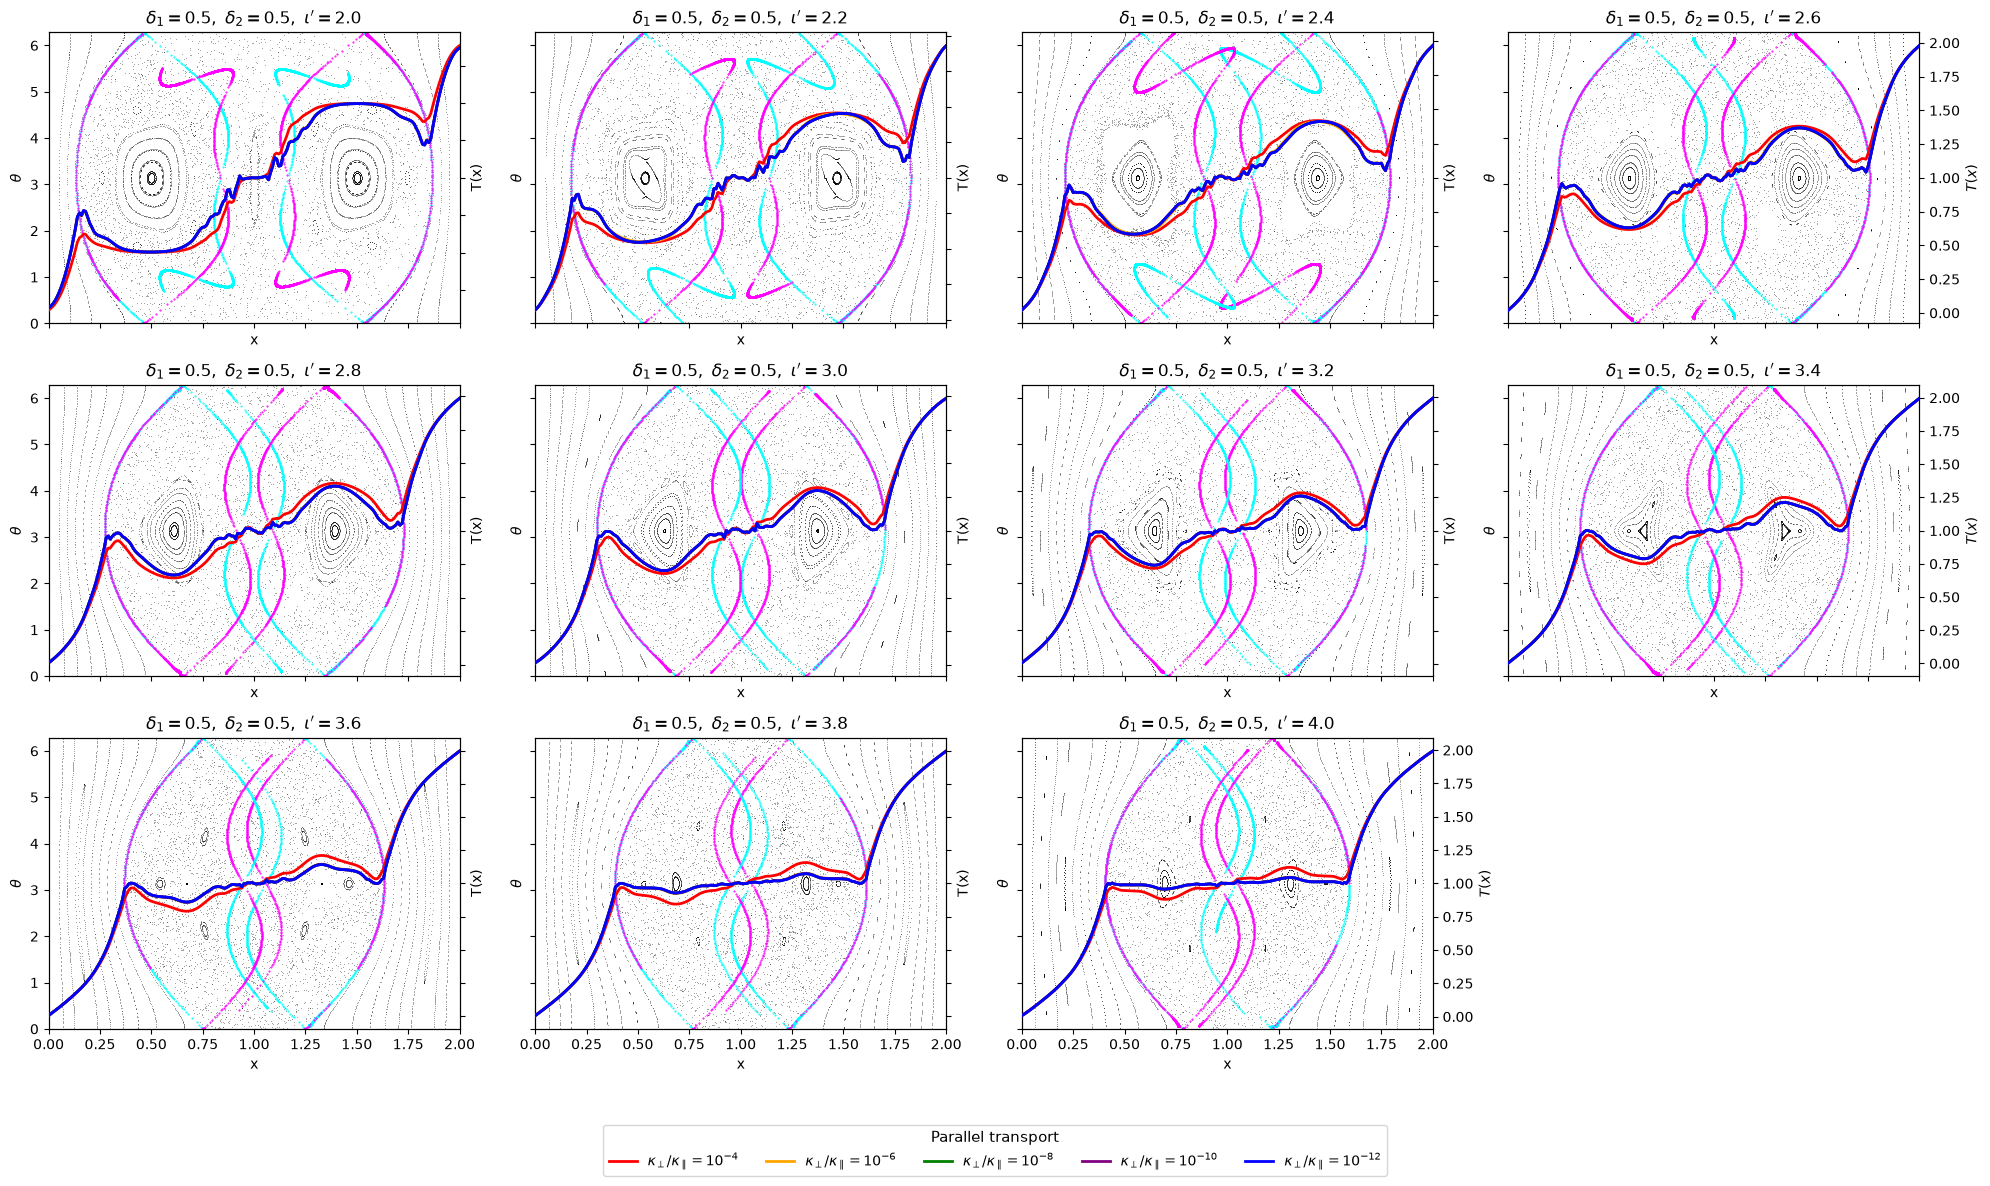

In [50]:
configs_1 = [12, 112, 111, 110, 19, 18, 17, 16, 15, 14, 13]

fig, ax = plot_configurations(
    configs_1,
    ncols=4,
    save_name="delta_0.5"
)

plt.show()

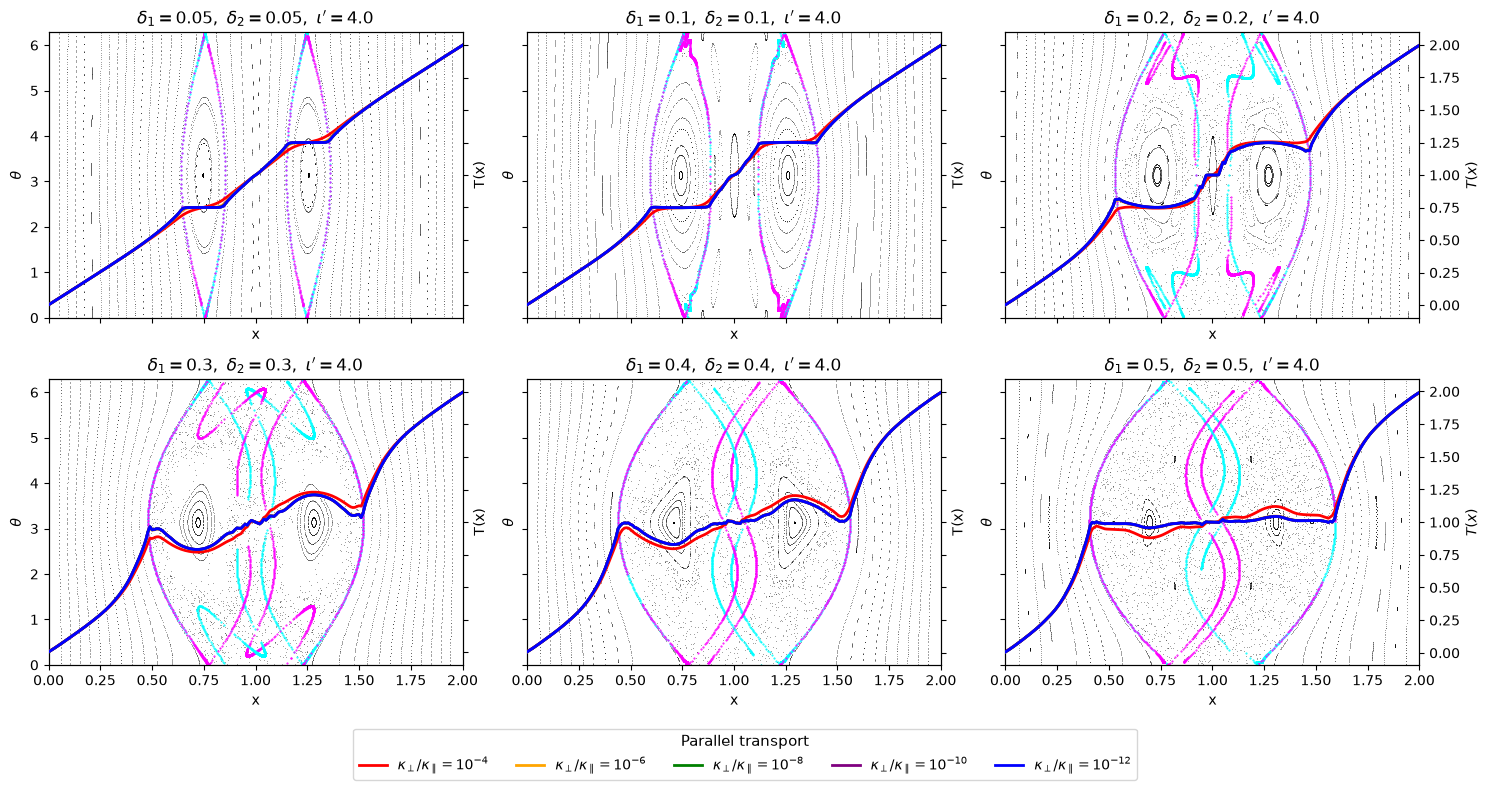

In [51]:
configs_2 = [115, 114, 113, 117, 116, 13]

fig, ax = plot_configurations(
    configs_2,
    ncols=3,
    save_name="iota_4.0"
)

plt.show()

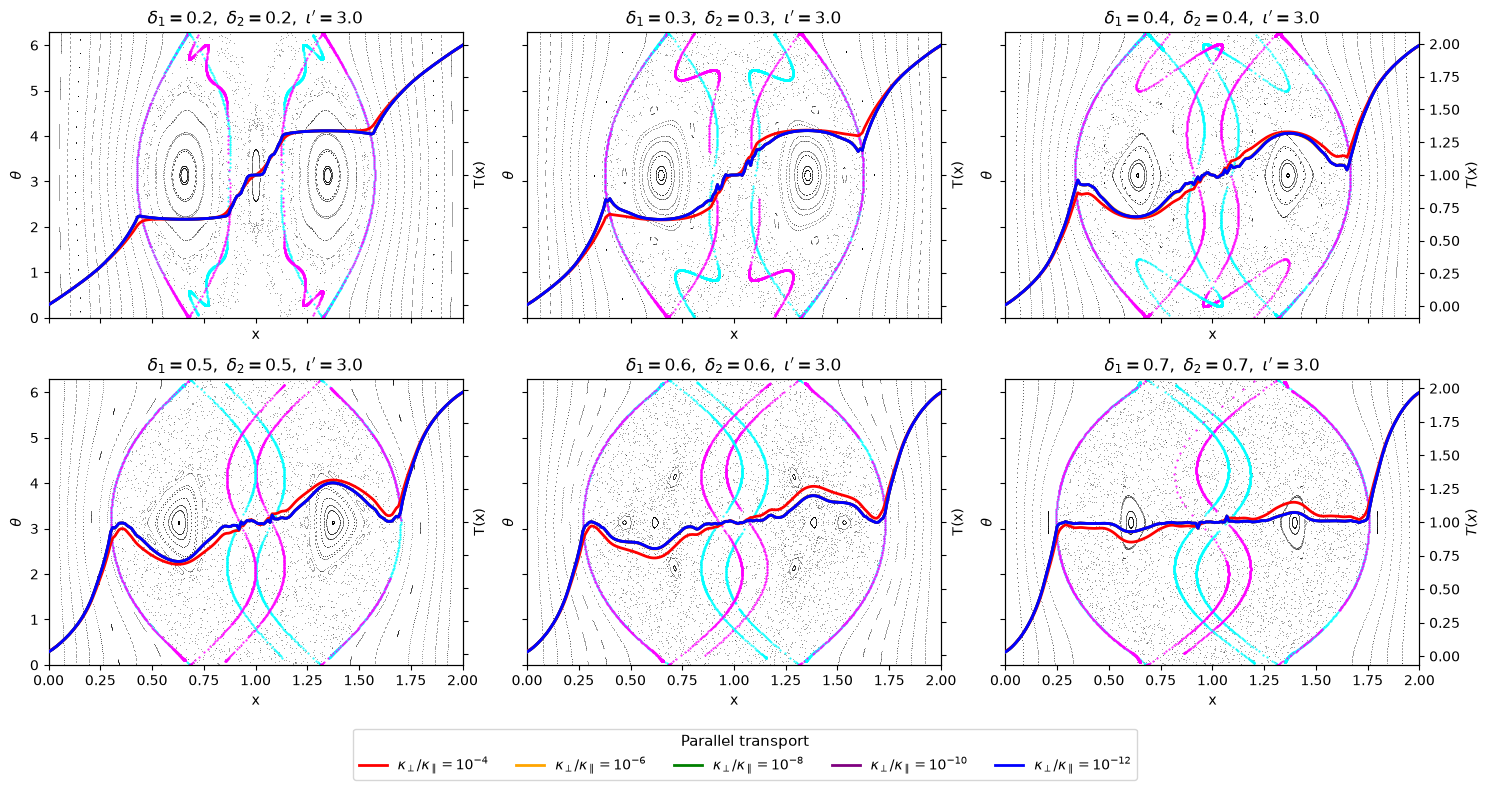

In [52]:
configs_3 = [118, 122, 123, 18, 120, 121] #119, 

fig, ax = plot_configurations(
    configs_3,
    ncols=3,
    save_name="iota_3.0"
)

plt.show()